In [7]:
import pandas as pd
import numpy as np

np.random.seed(42)

# Generate 5 distinct customer groups
groups = [
    (40, 25, 60),   # Low income, low spending
    (25, 75, 60),   # High income, low spending
    (75, 25, 60),   # Low income, high spending
    (75, 75, 60),   # High income, high spending
    (50, 50, 60)    # Average customers
]

data = []

customer_id = 1

for income_mean, spending_mean, size in groups:

    income = np.random.normal(income_mean, 8, size)
    spending = np.random.normal(spending_mean, 8, size)

    for i in range(size):

        data.append({
            "CustomerID": customer_id,
            "Annual_Income": income[i],
            "Spending_Score": spending[i]
        })

        customer_id += 1

df = pd.DataFrame(data)

# Keep values within realistic limits
df["Annual_Income"] = df["Annual_Income"].clip(15, 120)
df["Spending_Score"] = df["Spending_Score"].clip(1, 100)

df.head()

,CustomerID,Annual_Income,Spending_Score
0,1,43.973713,21.166606
1,2,38.893886,23.514728
2,3,45.181508,16.149320
3,4,52.184239,15.430347
4,5,38.126773,31.500207


In [8]:
df.shape

(300, 3)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      300 non-null    int64  
 1   Annual_Income   300 non-null    float64
 2   Spending_Score  300 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 7.2 KB


In [10]:
df.isnull().sum()

CustomerID        0
Annual_Income     0
Spending_Score    0
dtype: int64

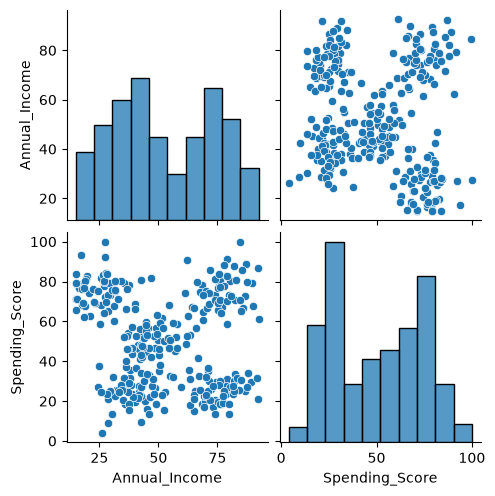

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(df[["Annual_Income", "Spending_Score"]])

plt.show()

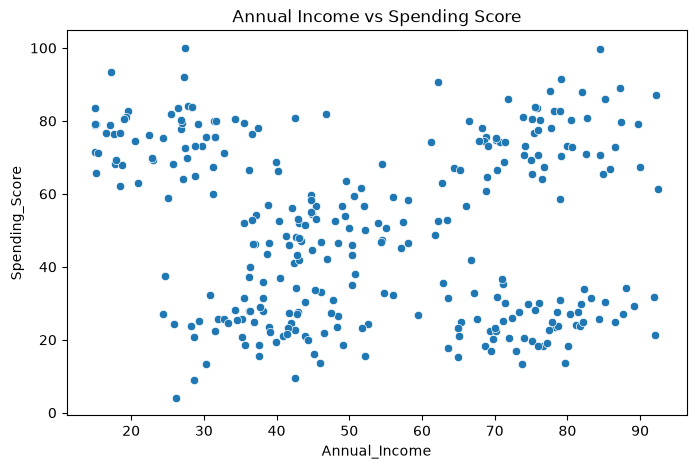

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score"
)

plt.title("Annual Income vs Spending Score")
plt.show()

In [15]:
from sklearn.preprocessing import StandardScaler

# K-Means ke liye relevant features
X = df[["Annual_Income", "Spending_Score"]]

# Scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


wcss = []
silhouette_scores = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    labels = kmeans.fit_predict(X_scaled)

    
    wcss.append(kmeans.inertia_)
    if k>=2:
        score = silhouette_score(
        X_scaled,
        labels
    )

        silhouette_scores.append((k,score))

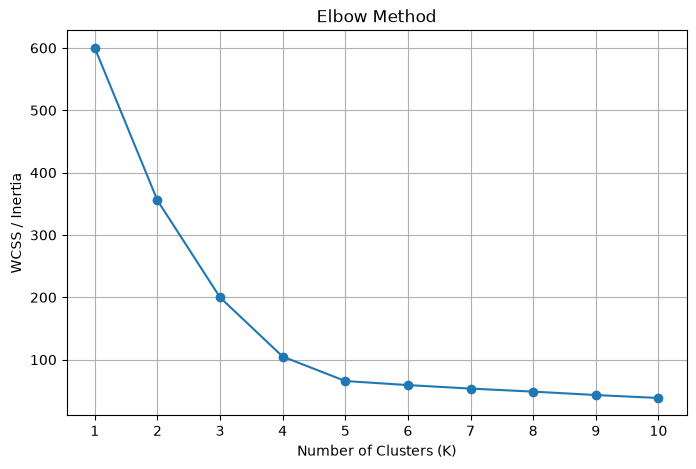

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")

plt.xticks(range(1, 11))
plt.grid()
plt.show()

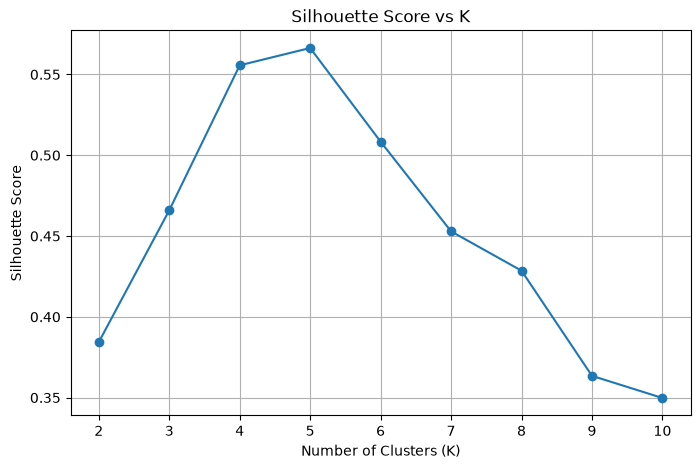

In [25]:
k_values = [item[0] for item in silhouette_scores]
scores = [item[1] for item in silhouette_scores]

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")

plt.xticks(k_values)
plt.grid()
plt.show()

In [31]:
kmeans = KMeans(
        n_clusters=5,
        init="k-means++",
        random_state=42,
        n_init=10
    )

kmeans.fit(X_scaled)
labels = kmeans.fit_predict(X_scaled)

In [32]:
df["Cluster"] = kmeans.labels_

df.head()

,CustomerID,Annual_Income,Spending_Score,Cluster
0,1,43.973713,21.166606,1
1,2,38.893886,23.514728,1
2,3,45.181508,16.149320,1
3,4,52.184239,15.430347,1
4,5,38.126773,31.500207,1


In [33]:
cluster_profile = df.groupby("Cluster")[
    ["Annual_Income", "Spending_Score"]
].mean().round(2)

cluster_profile

,Annual_Income,Spending_Score
Cluster,,
0,25.61,75.51
1,39.46,25.05
2,76.32,75.41
3,75.29,25.42
4,47.79,51.32


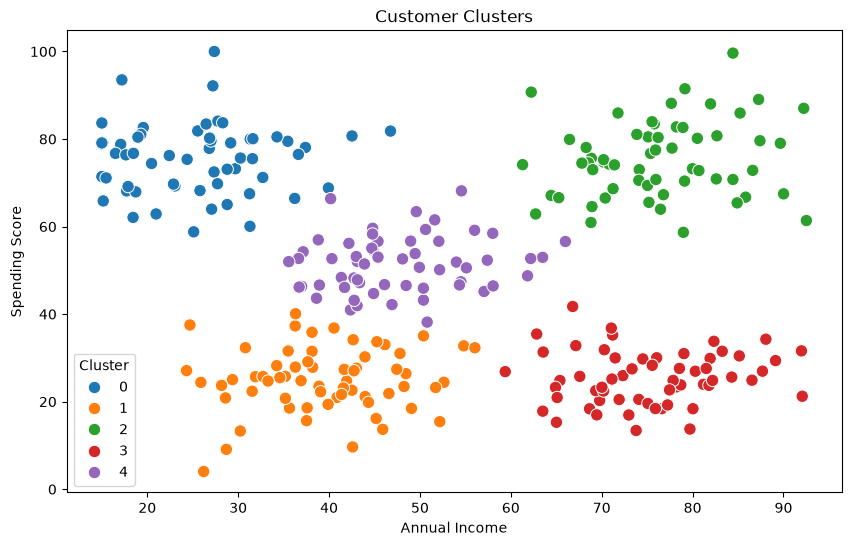

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="tab10",
    s=80
)

plt.title("Customer Clusters")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()